In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
run='svba34'
sim_end='2024080500'

In [3]:
# define flexpart output file path
path = '/jetfs/scratch/psplechtna/flexpart_output/'+run+'/'
filename_gridded = 'grid_time_'+sim_end+'0000.nc'

In [4]:
gridded = xr.open_dataset(path+filename_gridded, chunks={'time': 200})

In [5]:
mr = gridded.spec001_mr.sel(pointspec=5, nageclass=0, time='2024-07-12T00:00:00.000000000')
mass = gridded.spec001_mass.sel(pointspec=5, nageclass=0, time='2024-07-12T00:00:00.000000000')

In [6]:
h_mr = mr.sum(dim=['latitude', 'longitude'])
h_mass = mass.sum(dim=['latitude', 'longitude'])

In [7]:
h_mr.sum(dim='height').values

array(3596.4565, dtype=float32)

In [8]:
h_mass.sum(dim='height').values

array(3599.4253, dtype=float32)

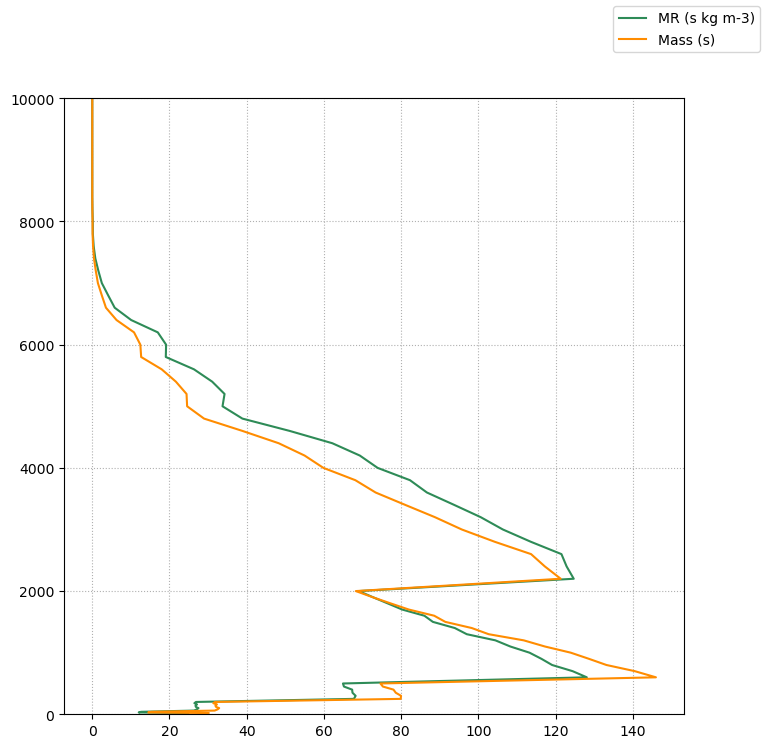

In [15]:
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(h_mr.values, h_mr.height, color='seagreen', label='MR (s kg m-3)')
ax.plot(h_mass.values, h_mass.height, color='darkorange', label='Mass (s)')

ax.grid(linestyle=':')
ax.set_ylim(0, 10000)
fig.legend()

In [12]:
scal_h = 9500

/tmp/ipykernel_767015/2211389880.py:1: RuntimeWarning: invalid value encountered in divide
  plt.plot(h_mass.values/h_mr.values, h_mr.height, color='darkorange', label='Mass (s)')


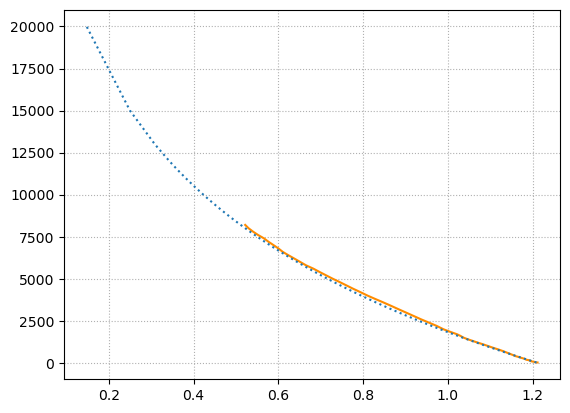

In [13]:
plt.plot(h_mass.values/h_mr.values, h_mr.height, color='darkorange', label='Mass (s)')
plt.plot(h_mass.values[0]/h_mr.values[0] * np.exp(-h_mass.height/scal_h), h_mr.height, linestyle=':')
#plt.ylim(0, 2000)
plt.grid(linestyle=':')